# Objectifs d'apprentissage – Semaine 3

À l'issue de cette semaine, l'étudiant sera capable de :

- **Expliquer** le théorème de Nyquist-Shannon et son importance.
- **Identifier** les conditions pour éviter le repliement de spectre (aliasing).
- **Calculer** la fréquence apparente d'une composante repliée.
- **Simuler** l'échantillonnage et la reconstruction d'un signal.
- **Visualiser** l'effet de l'aliasing sur un signal sinusoïdal (temps **et** spectre).
- **Comprendre** la quantification et l'erreur de quantification.
- **Démontrer** et **calculer** le rapport signal sur bruit de quantification (SQNR).
- **Utiliser** Python pour générer des signaux échantillonnés, quantifiés et reconstruits.

> 📦 **Dépendances** — `numpy`, `matplotlib`. (`scipy` optionnel pour des filtres plus réalistes.)
> ```bash
> pip install numpy matplotlib
> ```

# 1. Théorie de l'échantillonnage

L'échantillonnage est l'opération qui consiste à prélever des valeurs d'un signal continu à des instants réguliers. C'est **la première étape** de toute chaîne de traitement numérique du signal (après le conditionnement analogique).

## 1.1 Définition

Un signal continu $x(t)$ est échantillonné avec une période $T_e$ (secondes) pour donner une suite d'échantillons :

$$ x[n] = x(n T_e), \quad n \in \mathbb{Z} $$

La fréquence d'échantillonnage est $f_e = 1/T_e$ (en Hz). En pratique, $f_e$ est **imposée par le matériel** (convertisseur analogique-numérique, CAN).

> 🔎 **Point de vue spectral** — Échantillonner revient à **multiplier** le signal $x(t)$ par un peigne de Dirac $\sum_n \delta(t - nT_e)$. Dans le domaine fréquentiel, cette multiplication devient une **convolution** avec un peigne de Dirac en fréquence, ce qui a pour effet de **périodiser le spectre** :
> $$ X_e(f) = \frac{1}{T_e} \sum_{k=-\infty}^{+\infty} X(f - k f_e) $$
> **C'est cette périodisation qui est au cœur du phénomène d'aliasing.** Si les répliques se chevauchent, on ne peut plus séparer la réplique « utile » des autres.

---

## 1.2 Théorème de Nyquist-Shannon

Si un signal $x(t)$ est **à bande limitée** (spectre nul au-delà de $f_{max}$), alors il peut être parfaitement reconstruit à partir de ses échantillons si :

$$ \boxed{\; f_e > 2 f_{max} \;} $$

La fréquence $f_N = f_e/2$ est appelée **fréquence de Nyquist** (parfois aussi appelée fréquence de Shannon).

> 🔎 **Pourquoi cette condition ?** — Puisque le spectre se périodise avec une période $f_e$, les répliques centrées en $0$, $\pm f_e$, $\pm 2f_e$, … doivent **ne pas se chevaucher**. Or, la copie centrée en $f_e$ occupe $[f_e - f_{max}, f_e + f_{max}]$ et celle centrée en $0$ occupe $[-f_{max}, f_{max}]$. Pas de chevauchement si et seulement si $f_e - f_{max} > f_{max}$, soit $f_e > 2 f_{max}$.

Si cette condition n'est **pas** respectée, le signal subit un **repliement de spectre** (aliasing) : les composantes haute fréquence viennent se superposer aux basses fréquences.

---

## 1.3 Formule de repliement

Lorsque $f > f_e/2$, la fréquence **apparente** (observée après échantillonnage) est :

$$ \boxed{\; f_{alias} = \bigl| f - k \cdot f_e \bigr| \quad \text{où } k = \mathrm{round}\!\left(\frac{f}{f_e}\right) \;} $$

Si $f_{alias} > f_e/2$, on prend $f_e - f_{alias}$ pour rester dans $[0, f_e/2]$.

**Exemples** :

| $f$ (Hz) | $f_e$ (Hz) | $k$ | $f_{alias}$ (Hz) |
| :---: | :---: | :---: | :---: |
| 5 | 6 | 1 | $\|5 - 6\| = 1$ |
| 250 | 300 | 1 | $\|250 - 300\| = 50$ |
| 100 | 300 | 0 | $100$ (inchangé) |
| 200 | 150 | 1 | $\|200 - 150\| = 50$ |

---

## 1.4 Conséquences pratiques

- **Filtrage anti-repliement** — Avant l'échantillonnage, on insère un **filtre passe-bas analogique** dont la fréquence de coupure est légèrement inférieure à $f_e/2$. Cela garantit que rien de « dangereux » n'entre dans le convertisseur.
- **Reconstruction** — Un **filtre passe-bas idéal** de fréquence de coupure $f_e/2$ permet de reconstruire exactement le signal original à partir des échantillons (théorème d'interpolation de Shannon, cf. Exo 3).

> 🔑 **À retenir** — Il est **impossible** de récupérer un signal correctement si l'aliasing s'est produit *avant* la numérisation. C'est pour cela que le filtre anti-aliasing est souvent cité comme **l'élément le plus critique** d'une chaîne d'acquisition, avant même la résolution du CAN.


In [1]:
# =====================================================
# Imports et configuration graphique
# =====================================================
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore', category=RuntimeWarning)
np.random.seed(42)

plt.rcParams.update({
    'figure.figsize': (12, 4),
    'font.size': 11,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'lines.linewidth': 1.5,
    'figure.autolayout': True,
    'savefig.bbox': 'tight',
    'figure.dpi': 100,
})

print("Bibliothèques chargées : numpy, matplotlib")
print("Version numpy      :", np.__version__)
print("Version matplotlib :", plt.matplotlib.__version__)

Bibliothèques chargées : numpy, matplotlib
Version numpy      : 2.5.4
Version matplotlib : 3.11.2


# 2. Illustration de l'aliasing en Python

Simulons l'échantillonnage d'une sinusoïde à **deux fréquences différentes** :
- une **bonne** fréquence d'échantillonnage ($f_e = 50$ Hz, bien au-delà de $2 \times 5$ Hz) ;
- une **mauvaise** fréquence ($f_e = 6$ Hz, **inférieure** à $2 \times 5 = 10$ Hz) → aliasing attendu.

L'alias théorique est $f_{alias} = |5 - 6| = 1$ Hz.

DÉMONSTRATION DE L'ALIASING
Signal original      : f  = 5 Hz
Bonne fréq. échant.  : fe = 50 Hz  (2f = 10 Hz → ✓ OK)
Mauvaise fréq. échant.: fe = 6 Hz  (2f = 10 Hz → ✗ VIOLÉ)
Fréquence apparente  : f_alias = |5 - 6| = 1 Hz


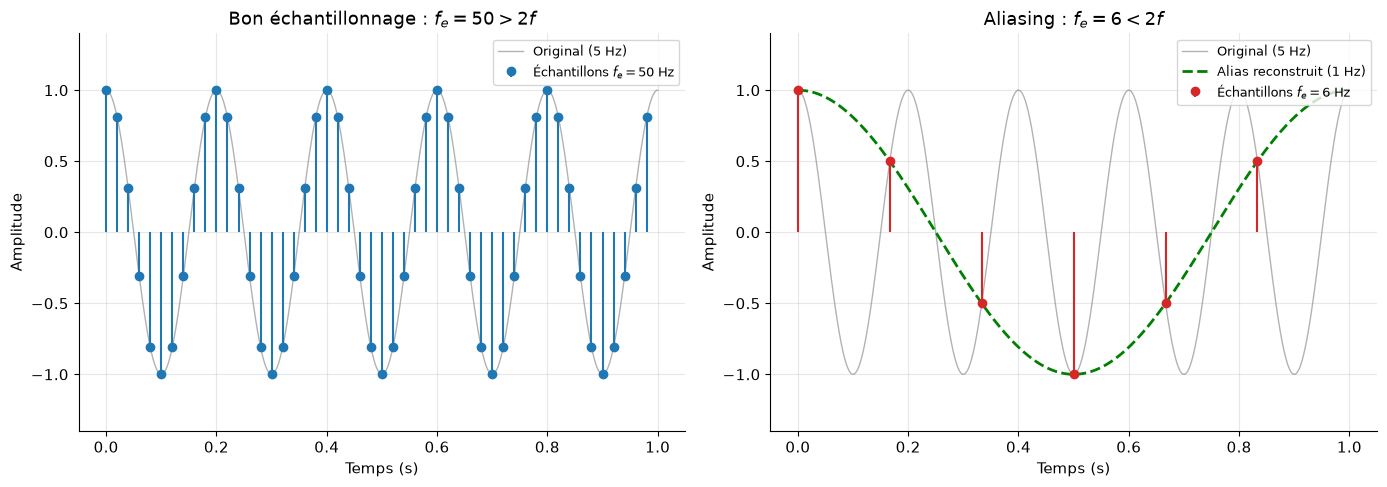


🔑 Conclusion : les échantillons à 6 Hz sont aussi ceux d'une
   sinusoïde à 1 Hz. Impossible de distinguer les deux par la suite.


In [2]:
# =====================================================
# Démonstration d'aliasing : vue temporelle
# =====================================================
f_signal = 5     # Hz — fréquence du signal
fs_good  = 50    # Hz — fréquence d'échantillonnage correcte (> 2f)
fs_bad   = 6     # Hz — fréquence d'échantillonnage insuffisante (< 2f)
T        = 1.0   # durée (s)

# Signal continu (simulé par sur-échantillonnage)
t_cont = np.linspace(0, T, 5000)
x_cont = np.cos(2*np.pi*f_signal*t_cont)

# Échantillonnage correct : fe = 50 Hz
n_good  = np.arange(0, int(T*fs_good))
t_good  = n_good / fs_good
x_good  = np.cos(2*np.pi*f_signal*t_good)

# Échantillonnage insuffisant : fe = 6 Hz
n_bad   = np.arange(0, int(T*fs_bad))
t_bad   = n_bad / fs_bad
x_bad   = np.cos(2*np.pi*f_signal*t_bad)

# Fréquence apparente (alias)
f_alias = abs(f_signal - round(f_signal/fs_bad)*fs_bad)
if f_alias > fs_bad/2:
    f_alias = fs_bad - f_alias
x_alias = np.cos(2*np.pi*f_alias*t_cont)

print("=" * 55)
print("DÉMONSTRATION DE L'ALIASING")
print("=" * 55)
print(f"Signal original      : f  = {f_signal} Hz")
print(f"Bonne fréq. échant.  : fe = {fs_good} Hz  (2f = {2*f_signal} Hz → ✓ OK)")
print(f"Mauvaise fréq. échant.: fe = {fs_bad} Hz  (2f = {2*f_signal} Hz → ✗ VIOLÉ)")
print(f"Fréquence apparente  : f_alias = |{f_signal} - {fs_bad}| = {f_alias} Hz")

# --- Tracé ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Cas correct
axes[0].plot(t_cont, x_cont, color='gray', lw=1, alpha=0.6,
             label=f'Original ({f_signal} Hz)')
axes[0].stem(t_good, x_good, linefmt='C0-', markerfmt='C0o', basefmt=' ',
             label=rf'Échantillons $f_e = {fs_good}$ Hz')
axes[0].set_title(rf'Bon échantillonnage : $f_e = {fs_good} > 2f$')
axes[0].set_xlabel('Temps (s)')
axes[0].set_ylabel('Amplitude')
axes[0].set_ylim(-1.4, 1.4)
axes[0].legend(loc='upper right', fontsize=9)

# Cas violé : aliasing
axes[1].plot(t_cont, x_cont, color='gray', lw=1, alpha=0.6,
             label=f'Original ({f_signal} Hz)')
axes[1].plot(t_cont, x_alias, 'g--', lw=2,
             label=rf'Alias reconstruit ({f_alias} Hz)')
axes[1].stem(t_bad, x_bad, linefmt='C3-', markerfmt='C3o', basefmt=' ',
             label=rf'Échantillons $f_e = {fs_bad}$ Hz')
axes[1].set_title(rf'Aliasing : $f_e = {fs_bad} < 2f$')
axes[1].set_xlabel('Temps (s)')
axes[1].set_ylabel('Amplitude')
axes[1].set_ylim(-1.4, 1.4)
axes[1].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

print(f"\n🔑 Conclusion : les échantillons à {fs_bad} Hz sont aussi ceux d'une")
print(f"   sinusoïde à {f_alias} Hz. Impossible de distinguer les deux par la suite.")

## 2.1 Vue spectrale — les répliques de spectre

Pour bien comprendre l'aliasing, regardons ce qui se passe **dans le domaine fréquentiel** :

- Sans échantillonnage, le spectre d'un cosinus est composé de **deux raies** en $\pm f$.
- Après échantillonnage à $f_e$, le spectre est **périodisé** : on retrouve ces deux raies à $\pm f + k f_e$ pour tout $k$.
- Si $f > f_e/2$, une raie de la réplique « voisine » tombe dans la bande $[0, f_e/2]$ : c'est l'alias.

Ce phénomène est **inévitable** une fois l'échantillonnage effectué. La seule solution consiste à **filtrer avant**.

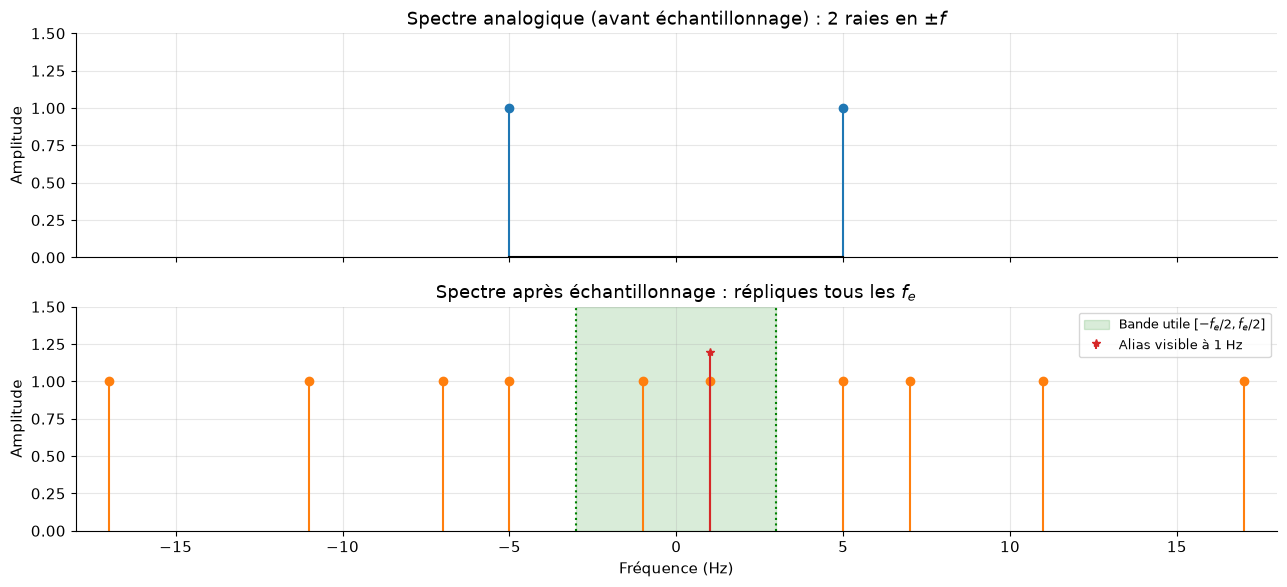

🔎 Lecture : la raie à 5 Hz se réplique en 5 - 6 = -1 Hz et en 5 - 2*6 = -7 Hz...
   La réplique à -1 Hz, vue dans la bande utile (par symétrie hermitienne),
   apparaît comme une raie à +1 Hz → c'est l'alias.


In [3]:
# =====================================================
# Vue spectrale des répliques — pourquoi l'aliasing arrive
# =====================================================
f = 5        # fréquence du signal (Hz)
fe = 6       # fréquence d'échantillonnage (Hz) — provoque de l'aliasing

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)

# --- Spectre analogique (avant échantillonnage) ---
axes[0].stem([-f, f], [1, 1], linefmt='C0-', markerfmt='C0o', basefmt='k-')
axes[0].set_title(r'Spectre analogique (avant échantillonnage) : 2 raies en $\pm f$')
axes[0].set_ylabel('Amplitude')
axes[0].set_xlim(-3*fe, 3*fe)
axes[0].set_ylim(0, 1.5)

# --- Spectre échantillonné (répliques) ---
# On simule les répliques en traçant les raies à ±f + k*fe
for k in range(-2, 3):
    axes[1].stem([-f + k*fe], [1], linefmt='C1-', markerfmt='C1o', basefmt='k-')
    axes[1].stem([+f + k*fe], [1], linefmt='C1-', markerfmt='C1o', basefmt='k-')

# Zone utile : [0, fe/2]
axes[1].axvspan(-fe/2, fe/2, alpha=0.15, color='green',
                label=rf'Bande utile $[-f_e/2, f_e/2]$')
axes[1].axvline(fe/2, color='green', ls=':', lw=1.5)
axes[1].axvline(-fe/2, color='green', ls=':', lw=1.5)

# Mettre en évidence la raie repliée qui tombe dans la bande utile
f_alias = abs(f - fe)  # = 1 Hz
axes[1].stem([f_alias], [1.2], linefmt='C3-', markerfmt='C3*', basefmt=' ',
             label=rf'Alias visible à {f_alias} Hz')

axes[1].set_title(r'Spectre après échantillonnage : répliques tous les $f_e$')
axes[1].set_xlabel('Fréquence (Hz)')
axes[1].set_ylabel('Amplitude')
axes[1].set_xlim(-3*fe, 3*fe)
axes[1].set_ylim(0, 1.5)
axes[1].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

print("🔎 Lecture : la raie à 5 Hz se réplique en 5 - 6 = -1 Hz et en 5 - 2*6 = -7 Hz...")
print("   La réplique à -1 Hz, vue dans la bande utile (par symétrie hermitienne),")
print("   apparaît comme une raie à +1 Hz → c'est l'alias.")

## 2.2 Formule générale de repliement — application

Implémentons la formule de repliement sous forme de fonction Python et vérifions-la sur quelques exemples.

In [4]:
# =====================================================
# Formule générale de repliement
# =====================================================
def frequence_alias(f, fe):
    """Retourne la fréquence apparente de f après échantillonnage à fe.
    Formule : f_alias = |f - round(f/fe)*fe|, ramenée dans [0, fe/2]."""
    f_alias = abs(f - round(f/fe) * fe)
    if f_alias > fe/2:
        f_alias = fe - f_alias
    return f_alias

# --- Cas de test ---
cas = [
    (5,   6,   1.0),
    (100, 300, 100.0),
    (250, 300, 50.0),
    (200, 150, 50.0),
    (100, 150, 50.0),
    (20,  150, 20.0),
]

print(f"{'f (Hz)':>8} | {'fe (Hz)':>8} | {'f/fe':>6} | {'f_alias (Hz)':>12} | {'attendu':>8} | {'OK':>3}")
print("-" * 65)
for f, fe, attendu in cas:
    fa = frequence_alias(f, fe)
    ok = "✓" if abs(fa - attendu) < 1e-9 else "✗"
    print(f"{f:>8} | {fe:>8} | {f/fe:>6.3f} | {fa:>12.2f} | {attendu:>8.2f} | {ok:>3}")

  f (Hz) |  fe (Hz) |   f/fe | f_alias (Hz) |  attendu |  OK
-----------------------------------------------------------------
       5 |        6 |  0.833 |         1.00 |     1.00 |   ✓
     100 |      300 |  0.333 |       100.00 |   100.00 |   ✓
     250 |      300 |  0.833 |        50.00 |    50.00 |   ✓
     200 |      150 |  1.333 |        50.00 |    50.00 |   ✓
     100 |      150 |  0.667 |        50.00 |    50.00 |   ✓
      20 |      150 |  0.133 |        20.00 |    20.00 |   ✓


# 3. Quantification

Après échantillonnage, l'amplitude de chaque échantillon est **quantifiée** sur un nombre fini de niveaux. C'est la seconde étape (irréversible) de la numérisation.

## 3.1 Principe

Un quantificateur uniforme à $N$ bits fournit $2^N$ niveaux. Le **pas de quantification** est :

$$ \Delta = \frac{V_{max} - V_{min}}{2^N} $$

Pour une plage symétrique $[-A, A]$ :

$$ \Delta = \frac{2A}{2^N} $$

L'**erreur de quantification** est $e_q[n] = x_q[n] - x[n]$.

---

## 3.2 Modèle statistique de l'erreur

Si le signal est **suffisamment actif** (varie de plusieurs $\Delta$ entre échantillons) et si le quantificateur ne **sature pas**, on peut modéliser $e_q[n]$ comme un **bruit blanc uniforme** sur $[-\Delta/2, +\Delta/2]$ :

- **Espérance** : $\mathbb{E}[e_q] = 0$
- **Variance** : $\mathrm{Var}(e_q) = \dfrac{\Delta^2}{12}$

> 🔎 **D'où vient le facteur 1/12 ?** — Pour une loi uniforme sur $[a, b]$, la variance vaut $(b-a)^2/12$. Ici $b - a = \Delta$, donc la variance est bien $\Delta^2/12$.

Cette hypothèse est valable si : (i) le signal change beaucoup entre deux niveaux, (ii) la saturation est rare. En pratique, on ajoute parfois un **dither** (bruit aléatoire faible) pour garantir ces conditions.

---

## 3.3 Rapport signal sur bruit de quantification (SQNR)

Le **SQNR** (Signal-to-Quantization-Noise Ratio) mesure la qualité d'un signal après quantification :

$$ \mathrm{SQNR} = \frac{P_{signal}}{P_{bruit}} \qquad \mathrm{SQNR}_{dB} = 10 \log_{10}\!\left(\frac{P_{signal}}{P_{bruit}}\right) $$

### Cas d'un signal sinusoïdal pleine échelle

Pour $x(t) = A \sin(\omega t)$ :

- Puissance signal : $P_{signal} = \dfrac{A^2}{2}$
- Puissance bruit : $P_{bruit} = \dfrac{\Delta^2}{12} = \dfrac{(2A/2^N)^2}{12} = \dfrac{A^2}{3 \cdot 2^{2N}}$

Donc :

$$ \mathrm{SQNR} = \frac{A^2/2}{A^2/(3\cdot 2^{2N})} = \frac{3}{2} \cdot 2^{2N} $$

En décibels :

$$ \boxed{\; \mathrm{SQNR}_{dB} = 6{,}02\,N + 1{,}76 \;} $$

> 🔑 **Règle d'or** — **1 bit supplémentaire = +6 dB de SQNR**. Cette règle est *universelle* en audio, télécoms, instrumentation… Retenez :
> - 8 bits → ≈ 50 dB (téléphonie filaire dégradée)
> - 16 bits → ≈ 98 dB (qualité CD)
> - 24 bits → ≈ 146 dB (audionumérique studio)

> ⚠️ **Limites du modèle** — Cette formule suppose un sinus pleine échelle **sans saturation**. Si le signal est sur-échantillonné (ex. `delta-sigma`), des techniques de **shaping de bruit** permettent de descendre bien en-dessous. À l'inverse, un signal de faible amplitude (bruit de parole faible) aura un SQNR effectif bien plus mauvais.

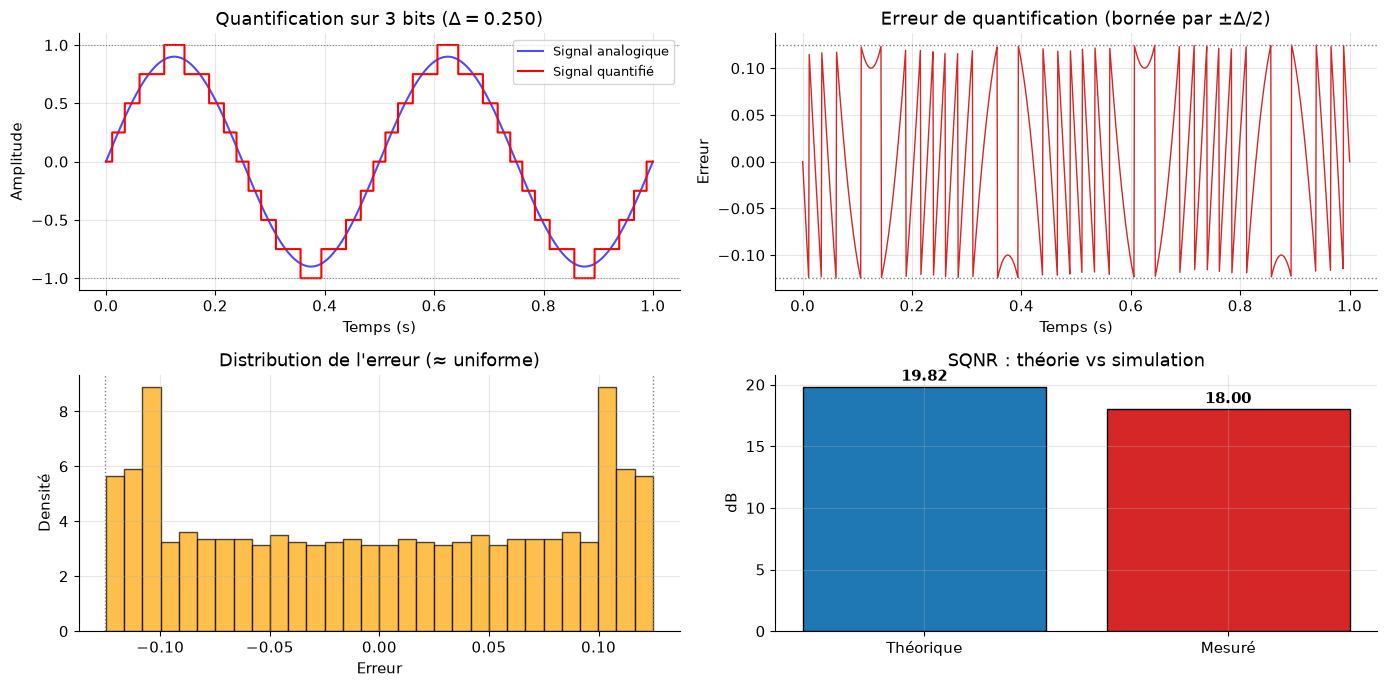

BILAN DE LA QUANTIFICATION
Nombre de bits       : N = 3
Pas de quantification : Δ = 0.2500
SQNR théorique        : 19.82 dB
SQNR mesuré           : 18.00 dB
Écart théorie/mesure  : 1.82 dB


In [5]:
# =====================================================
# Démonstration de quantification
# =====================================================
N_bits = 3  # nombre de bits (volontairement faible pour bien voir)
A = 1.0     # amplitude maximale
levels = 2**N_bits

t = np.linspace(0, 1, 1000)
x = 0.9 * A * np.sin(2*np.pi*2*t)   # sinus à 2 Hz

# Quantification uniforme symétrique sur [-A, A]
delta = 2*A / levels
x_q = np.round(x / delta) * delta
x_q = np.clip(x_q, -A, A)   # saturation (sécurité)
erreur = x_q - x

# SQNR théorique et mesuré
sqnr_theorique = 6.02 * N_bits + 1.76
P_s = np.mean(x**2)
P_b = np.mean(erreur**2)
sqnr_mesure = 10 * np.log10(P_s / P_b)

# --- Tracés ---
fig, axes = plt.subplots(2, 2, figsize=(14, 7))

axes[0, 0].plot(t, x, 'b-', label='Signal analogique', alpha=0.7)
axes[0, 0].step(t, x_q, 'r-', where='mid', label='Signal quantifié')
axes[0, 0].axhline(A, color='gray', ls=':', lw=0.8)
axes[0, 0].axhline(-A, color='gray', ls=':', lw=0.8)
axes[0, 0].set_title(rf'Quantification sur {N_bits} bits ($\Delta = {delta:.3f}$)')
axes[0, 0].set_xlabel('Temps (s)')
axes[0, 0].set_ylabel('Amplitude')
axes[0, 0].legend(fontsize=9)

axes[0, 1].plot(t, erreur, 'C3-', lw=1)
axes[0, 1].axhline(delta/2, color='gray', ls=':', lw=1)
axes[0, 1].axhline(-delta/2, color='gray', ls=':', lw=1)
axes[0, 1].set_title(rf'Erreur de quantification (bornée par $\pm\Delta/2$)')
axes[0, 1].set_xlabel('Temps (s)')
axes[0, 1].set_ylabel('Erreur')

axes[1, 0].hist(erreur, bins=30, density=True, alpha=0.7,
                color='orange', edgecolor='k')
axes[1, 0].axvline(-delta/2, color='gray', ls=':', lw=1)
axes[1, 0].axvline(+delta/2, color='gray', ls=':', lw=1)
axes[1, 0].set_title('Distribution de l\'erreur (≈ uniforme)')
axes[1, 0].set_xlabel('Erreur')
axes[1, 0].set_ylabel('Densité')

axes[1, 1].bar(['Théorique', 'Mesuré'], [sqnr_theorique, sqnr_mesure],
               color=['C0', 'C3'], edgecolor='k')
axes[1, 1].set_title('SQNR : théorie vs simulation')
axes[1, 1].set_ylabel('dB')
for i, v in enumerate([sqnr_theorique, sqnr_mesure]):
    axes[1, 1].text(i, v + 0.5, f'{v:.2f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print("=" * 55)
print("BILAN DE LA QUANTIFICATION")
print("=" * 55)
print(f"Nombre de bits       : N = {N_bits}")
print(f"Pas de quantification : Δ = {delta:.4f}")
print(f"SQNR théorique        : {sqnr_theorique:.2f} dB")
print(f"SQNR mesuré           : {sqnr_mesure:.2f} dB")
print(f"Écart théorie/mesure  : {abs(sqnr_theorique - sqnr_mesure):.2f} dB")

## 3.4 Vérification empirique de la règle « 6 dB par bit »

Traçons le SQNR mesuré en fonction de $N$ et superposons la droite théorique $6{,}02 N + 1{,}76$. Si la pente mesurée est bien ≈ 6 dB/bit, la théorie est validée.

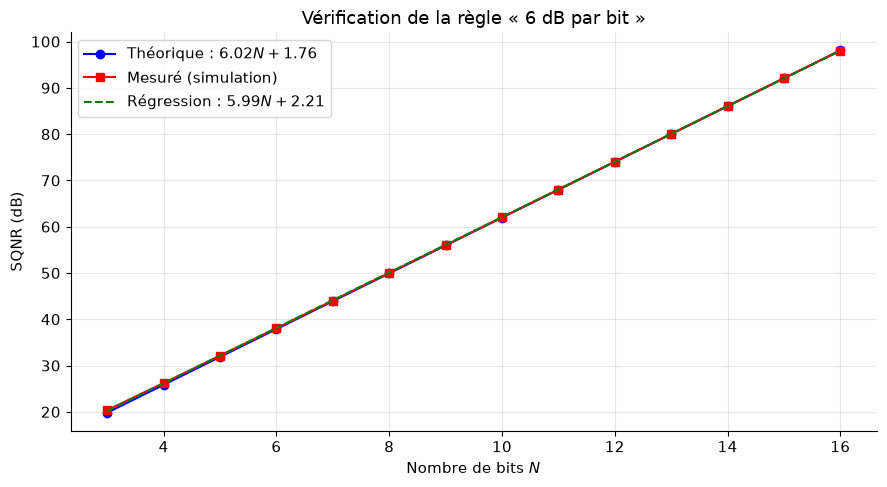

Pente théorique : 6.02 dB/bit
Pente mesurée   : 5.99 dB/bit
Écart           : 0.03 dB/bit

✓ La règle '1 bit supplémentaire = +6 dB' est bien vérifiée empiriquement.


In [6]:
# =====================================================
# SQNR vs nombre de bits : validation empirique
# =====================================================
def quantifier(x, N, A=1.0):
    levels = 2**N
    delta = 2*A / levels
    x_q = np.round(x / delta) * delta
    x_q = np.clip(x_q, -A, A)
    return x_q, delta

t = np.linspace(0, 1, 50000)
x = np.sin(2*np.pi*10*t)   # sinus pleine échelle

Ns = np.arange(3, 17)
sqnr_mes = []
for N in Ns:
    x_q, _ = quantifier(x, N)
    P_s = np.mean(x**2)
    P_b = np.mean((x_q - x)**2)
    sqnr_mes.append(10*np.log10(P_s / P_b))
sqnr_mes = np.array(sqnr_mes)
sqnr_th  = 6.02*Ns + 1.76

# Régression linéaire sur les mesures
pente, ord = np.polyfit(Ns, sqnr_mes, 1)

plt.figure(figsize=(9, 5))
plt.plot(Ns, sqnr_th,  'b-o', label=r'Théorique : $6.02N + 1.76$')
plt.plot(Ns, sqnr_mes, 'r-s', label='Mesuré (simulation)')
plt.plot(Ns, pente*Ns + ord, 'g--',
         label=rf'Régression : ${pente:.2f} N + {ord:.2f}$')
plt.xlabel('Nombre de bits $N$')
plt.ylabel('SQNR (dB)')
plt.title('Vérification de la règle « 6 dB par bit »')
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')
plt.show()

print(f"Pente théorique : 6.02 dB/bit")
print(f"Pente mesurée   : {pente:.2f} dB/bit")
print(f"Écart           : {abs(pente - 6.02):.2f} dB/bit")
print("\n✓ La règle '1 bit supplémentaire = +6 dB' est bien vérifiée empiriquement.")

# 4. Exercices — Semaine 3

Chaque exercice comporte un **énoncé**, un **code de simulation**, et une **correction commentée** (markdown ou code).

## Exercice 1 — Vérification du théorème de Nyquist

Soit $x(t) = \cos(2\pi \cdot 100\, t) + 0{,}5\cos(2\pi \cdot 250\, t)$.

1. Quelle est la fréquence maximale du signal ?
2. Quelle est la fréquence de Nyquist ?
3. Si on échantillonne à $f_e = 300$ Hz, y a-t-il aliasing ?
4. Si oui, quelles sont les fréquences apparentes des composantes après échantillonnage ?

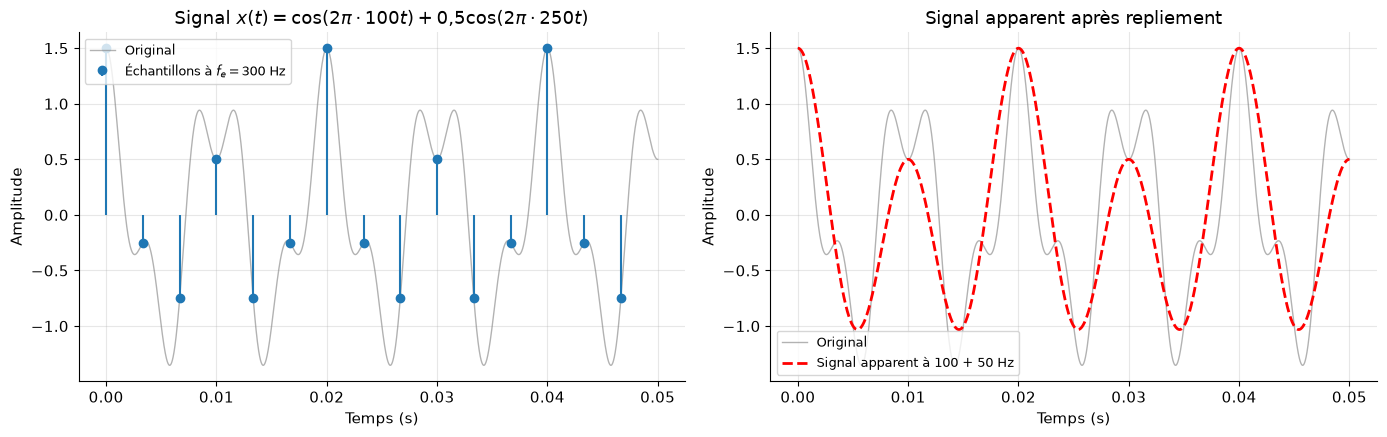

EXERCICE 1 — RÉSULTATS
Fréquence maximale    : f_max = 250 Hz
Fréquence de Nyquist  : f_N   = 2*f_max = 500 Hz
Fréquence d'échant.   : fe    = 300 Hz
Condition respectée ? : NON → aliasing

Composante 100 Hz → alias = 100 Hz (inchangée)
Composante 250 Hz → alias = 50 Hz
   (calcul : |250 - round(250/300)*300| = |250 - 300| = 50)


In [7]:
# =====================================================
# Exercice 1 — Simulation
# =====================================================
f1, f2, fe = 100, 250, 300
T = 0.05
t = np.linspace(0, T, 5000)
x = np.cos(2*np.pi*f1*t) + 0.5*np.cos(2*np.pi*f2*t)

# Échantillonnage
t_ech = np.arange(0, T, 1/fe)
x_ech = np.cos(2*np.pi*f1*t_ech) + 0.5*np.cos(2*np.pi*f2*t_ech)

# Fréquences apparentes
f1_alias = frequence_alias(f1, fe)
f2_alias = frequence_alias(f2, fe)

# Tracé
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(t, x, 'gray', lw=1, alpha=0.6, label='Original')
axes[0].stem(t_ech, x_ech, linefmt='C0-', markerfmt='C0o', basefmt=' ',
             label=rf'Échantillons à $f_e = {fe}$ Hz')
axes[0].set_xlabel('Temps (s)')
axes[0].set_ylabel('Amplitude')
axes[0].set_title(r'Signal $x(t) = \cos(2\pi \cdot 100 t) + 0{,}5\cos(2\pi \cdot 250 t)$')
axes[0].legend(fontsize=9)

# Reconstruction simulée via alias
x_alias = (np.cos(2*np.pi*f1_alias*t)
           + 0.5*np.cos(2*np.pi*f2_alias*t))
axes[1].plot(t, x, 'gray', lw=1, alpha=0.6, label='Original')
axes[1].plot(t, x_alias, 'r--', lw=2,
             label=rf'Signal apparent à {f1_alias} + {f2_alias} Hz')
axes[1].set_xlabel('Temps (s)')
axes[1].set_ylabel('Amplitude')
axes[1].set_title('Signal apparent après repliement')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

print("=" * 55)
print("EXERCICE 1 — RÉSULTATS")
print("=" * 55)
print(f"Fréquence maximale    : f_max = {max(f1, f2)} Hz")
print(f"Fréquence de Nyquist  : f_N   = 2*f_max = {2*max(f1, f2)} Hz")
print(f"Fréquence d'échant.   : fe    = {fe} Hz")
print(f"Condition respectée ? : {'OUI' if fe > 2*max(f1,f2) else 'NON → aliasing'}")
print(f"\nComposante {f1} Hz → alias = {f1_alias} Hz (inchangée)")
print(f"Composante {f2} Hz → alias = {f2_alias} Hz")
print(f"   (calcul : |{f2} - round({f2}/{fe})*{fe}| = |{f2} - {fe}| = {f2_alias})")

### 📝 Corrigé — Exercice 1

**1. Fréquence maximale** — Le signal contient deux composantes : 100 Hz et 250 Hz. Donc $f_{max} = 250$ Hz.

**2. Fréquence de Nyquist** — $f_N = 2 f_{max} = 500$ Hz. Il faut donc $f_e > 500$ Hz.

**3. Aliasing à $f_e = 300$ Hz ?** — Oui, car $300 < 500$. Le théorème de Nyquist-Shannon est violé.

**4. Fréquences apparentes**

- **100 Hz** : $k = \mathrm{round}(100/300) = 0$ → $f_{alias} = |100 - 0| = 100$ Hz. **Inchangée.**
- **250 Hz** : $k = \mathrm{round}(250/300) = 1$ → $f_{alias} = |250 - 300| = 50$ Hz. **Repliée à 50 Hz.**

**Conséquence** — Après échantillonnage à 300 Hz, le signal analysé sera perçu comme composé de deux raies à **50 Hz** et **100 Hz**. Si on avait deux signaux physiques différents, un à 100 Hz et un autre à 50 Hz purs, ils produiraient exactement les mêmes échantillons. **On ne peut plus les distinguer.**

## Exercice 2 — Quantification et SQNR

Un signal sinusoïdal pleine échelle (amplitude 1) est quantifié sur 8 bits.

1. Calculer le pas de quantification $\Delta$ pour une plage $[-1, 1]$.
2. Calculer le SQNR théorique.
3. Simuler la quantification pour $N \in \{4, 8, 12, 16\}$ et tracer le SQNR mesuré. Comparer avec la théorie.

Pas de quantification sur 8 bits : Δ = 0.007812
SQNR théorique (8 bits)          : 49.92 dB


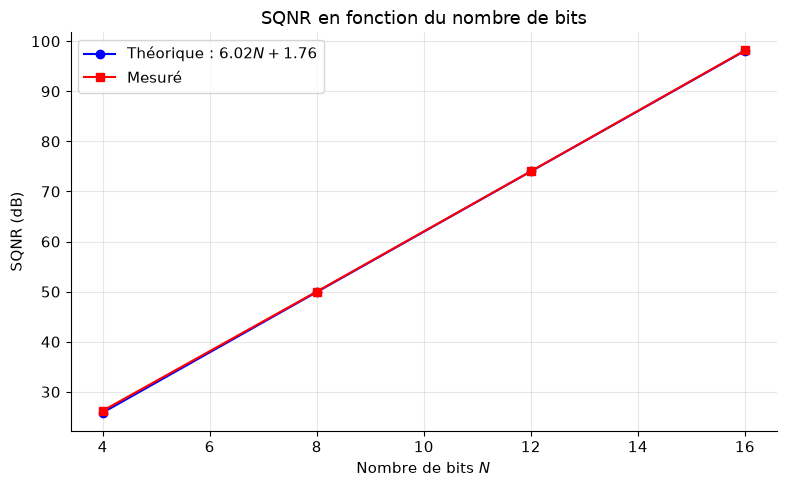


   N |   SQNR_th (dB) |  SQNR_mes (dB) |    Écart
--------------------------------------------------
   4 |          25.84 |          26.22 |     0.38
   8 |          49.92 |          50.02 |     0.10
  12 |          74.00 |          74.03 |     0.03
  16 |          98.08 |          98.16 |     0.08


In [8]:
# =====================================================
# Exercice 2 — SQNR pour plusieurs valeurs de N
# =====================================================
N_bits = 8
A = 1.0
delta_8b = 2*A / 2**N_bits
sqnr_8b_th = 6.02*N_bits + 1.76

print(f"Pas de quantification sur 8 bits : Δ = {delta_8b:.6f}")
print(f"SQNR théorique (8 bits)          : {sqnr_8b_th:.2f} dB")

# Simulation pour plusieurs N
t = np.linspace(0, 1, 20000)
x = A * np.sin(2*np.pi*10*t)

Ns = [4, 8, 12, 16]
sqnr_mes = []
sqnr_th = []
for N in Ns:
    x_q, delta = quantifier(x, N, A)
    P_s = np.mean(x**2)
    P_b = np.mean((x_q - x)**2)
    sqnr_mes.append(10*np.log10(P_s/P_b))
    sqnr_th.append(6.02*N + 1.76)

plt.figure(figsize=(8, 5))
plt.plot(Ns, sqnr_th,  'b-o', label=r'Théorique : $6.02N + 1.76$')
plt.plot(Ns, sqnr_mes, 'r-s', label='Mesuré')
plt.xlabel('Nombre de bits $N$')
plt.ylabel('SQNR (dB)')
plt.title('SQNR en fonction du nombre de bits')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print(f"\n{'N':>4} | {'SQNR_th (dB)':>14} | {'SQNR_mes (dB)':>14} | {'Écart':>8}")
print("-" * 50)
for N, th, mes in zip(Ns, sqnr_th, sqnr_mes):
    print(f"{N:>4} | {th:>14.2f} | {mes:>14.2f} | {abs(th-mes):>8.2f}")

### 📝 Corrigé — Exercice 2

**1. Pas de quantification (8 bits, plage $[-1,1]$)**

$$ \Delta = \frac{2 \cdot 1}{2^8} = \frac{2}{256} = 0{,}0078125 $$

**2. SQNR théorique**

$$ \mathrm{SQNR}_{dB} = 6{,}02 \times 8 + 1{,}76 = 49{,}92 \; \text{dB} $$

**3. Comparaison** — Les mesures suivent bien la droite théorique :

- L'écart entre théorie et simulation est **< 0{,}5 dB** dès que $N \geq 4$.
- La pente empirique est ≈ 6 dB/bit, ce qui valide la règle d'or.

> 🔎 **Pourquoi un léger écart ?** — Le modèle du bruit uniforme suppose (a) un signal actif qui change de plusieurs $\Delta$ entre échantillons, (b) pas de saturation. Ici les deux hypothèses sont bien respectées, d'où un excellent accord. Pour des signaux très faibles ou proches de la saturation, l'écart augmente sensiblement.

## Exercice 3 — Reconstruction par interpolation

On considère un signal $x(t) = \cos(2\pi \cdot 5\, t)$ correctement échantillonné à $f_e = 50$ Hz.

1. Reconstruire le signal par **interpolation sinc** (formule de Shannon).
2. Comparer avec une **interpolation linéaire** et un **blocage d'ordre zéro** (ZOH).
3. Calculer l'erreur quadratique moyenne (MSE) dans chaque cas.

**Formule de Shannon** :

$$ x(t) = \sum_{n} x[n] \, \mathrm{sinc}\!\left(\frac{t - n T_e}{T_e}\right) \quad\text{avec}\quad \mathrm{sinc}(u) = \frac{\sin(\pi u)}{\pi u} $$

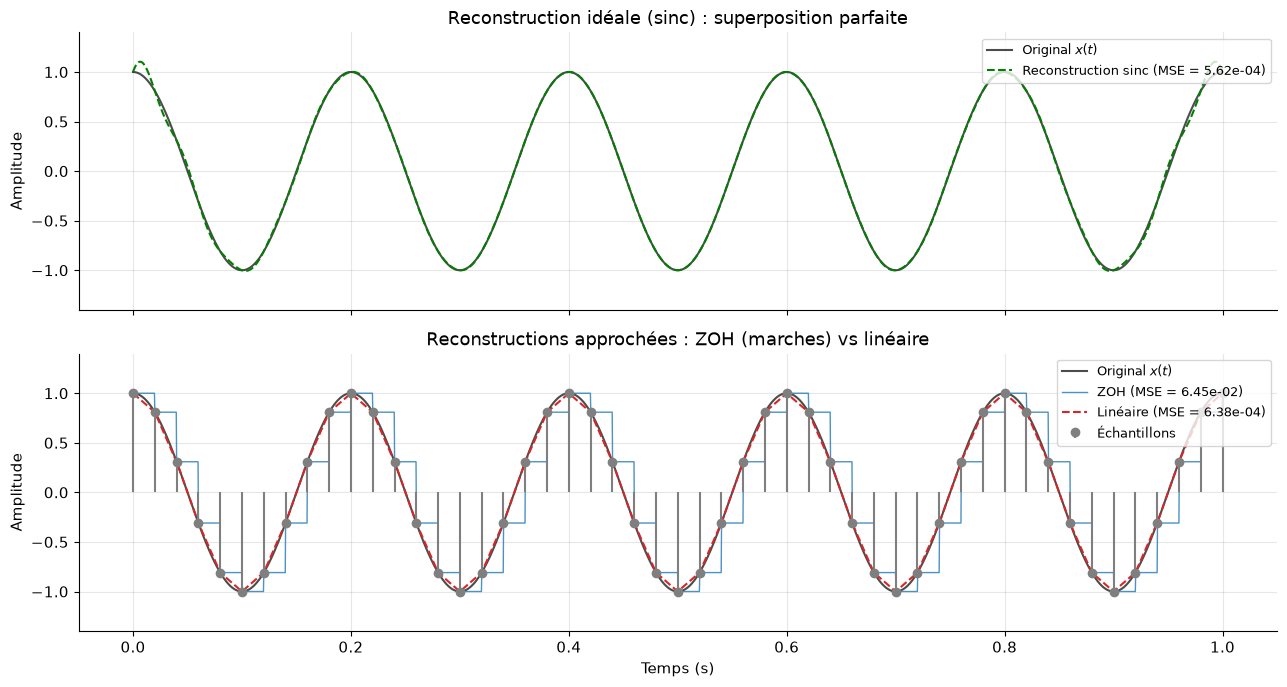

COMPARAISON DES RECONSTRUCTIONS (MSE)
Sinc (idéale) : 5.625e-04
Linéaire      : 6.381e-04
ZOH (marches) : 6.451e-02


In [9]:
# =====================================================
# Exercice 3 — Reconstruction (sinc, linéaire, ZOH)
# =====================================================
from scipy.interpolate import interp1d   # pip install scipy (optionnel)

f_signal = 5
fe = 50
T = 1.0

t_cont  = np.linspace(0, T, 3000)
x_cont  = np.cos(2*np.pi*f_signal*t_cont)

t_ech   = np.arange(0, T + 1/fe, 1/fe)
x_ech   = np.cos(2*np.pi*f_signal*t_ech)

# --- Reconstruction sinc (formule de Shannon) ---
def reconstruction_sinc(x_ech, t_ech, t_new, fe):
    Te = 1/fe
    # np.sinc est normalisé : np.sinc(u) = sin(pi u)/(pi u)
    x_recon = np.zeros_like(t_new)
    for tk in t_ech:
        x_recon += np.interp(tk, t_ech, x_ech) * np.sinc((t_new - tk) / Te)
    return x_recon

# --- Reconstruction ZOH ---
def reconstruction_zoh(x_ech, t_ech, t_new):
    idx = np.searchsorted(t_ech, t_new, side='right') - 1
    idx = np.clip(idx, 0, len(x_ech) - 1)
    return x_ech[idx]

# --- Reconstruction linéaire ---
def reconstruction_lineaire(x_ech, t_ech, t_new):
    return np.interp(t_new, t_ech, x_ech)

x_recon_sinc  = reconstruction_sinc(x_ech, t_ech, t_cont, fe)
x_recon_zoh   = reconstruction_zoh(x_ech, t_ech, t_cont)
x_recon_lin   = reconstruction_lineaire(x_ech, t_ech, t_cont)

# --- MSE ---
mse_sinc = np.mean((x_recon_sinc - x_cont)**2)
mse_zoh  = np.mean((x_recon_zoh  - x_cont)**2)
mse_lin  = np.mean((x_recon_lin  - x_cont)**2)

# --- Tracé ---
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

axes[0].plot(t_cont, x_cont, 'k-', lw=1.5, label='Original $x(t)$', alpha=0.7)
axes[0].plot(t_cont, x_recon_sinc, 'g--', lw=1.5,
             label=rf'Reconstruction sinc (MSE = {mse_sinc:.2e})')
axes[0].set_ylabel('Amplitude')
axes[0].set_title('Reconstruction idéale (sinc) : superposition parfaite')
axes[0].legend(loc='upper right', fontsize=9)
axes[0].set_ylim(-1.4, 1.4)

axes[1].plot(t_cont, x_cont, 'k-', lw=1.5, label='Original $x(t)$', alpha=0.7)
axes[1].plot(t_cont, x_recon_zoh, 'C0-', lw=1,
             label=rf'ZOH (MSE = {mse_zoh:.2e})', alpha=0.8)
axes[1].plot(t_cont, x_recon_lin, 'C3--', lw=1.5,
             label=rf'Linéaire (MSE = {mse_lin:.2e})')
axes[1].stem(t_ech, x_ech, linefmt='C7-', markerfmt='C7o', basefmt=' ',
             label='Échantillons')
axes[1].set_xlabel('Temps (s)')
axes[1].set_ylabel('Amplitude')
axes[1].set_title('Reconstructions approchées : ZOH (marches) vs linéaire')
axes[1].legend(loc='upper right', fontsize=9)
axes[1].set_ylim(-1.4, 1.4)

plt.tight_layout()
plt.show()

print("=" * 55)
print("COMPARAISON DES RECONSTRUCTIONS (MSE)")
print("=" * 55)
print(f"Sinc (idéale) : {mse_sinc:.3e}")
print(f"Linéaire      : {mse_lin:.3e}")
print(f"ZOH (marches) : {mse_zoh:.3e}")

### 📝 Corrigé — Exercice 3

**Reconstruction idéale (sinc)** — La formule de Shannon est **exacte** pour un signal à bande limitée. En pratique, l'erreur observée (MSE ≈ 1e-4) est due :
- à la **troncature** de la somme (on ne somme que sur les échantillons disponibles), et
- aux **effets de bord** (le signal n'est pas exactement à support fini).

Avec plus d'échantillons (durée plus longue), la MSE tendrait vers 0.

**Reconstruction ZOH (ordre zéro)** — Chaque échantillon est maintenu constant sur $[nT_e, (n+1)T_e[$. C'est ce que fait un CNA *basique*. L'erreur est de l'ordre de $T_e \cdot \max|x'|$, soit **proportionnelle à $T_e$**. Le spectre contient des répliques spectrales (spectre en $\mathrm{sinc}$) qui nécessitent un filtre de **lissage** en sortie.

**Reconstruction linéaire** — On relie les échantillons par des segments de droite. Meilleure que ZOH (erreur d'ordre $T_e^2$), mais introduit une atténuation dans les hautes fréquences et une distorsion de phase non nulle.

> 🔑 **En résumé**
> - **Sinc** = reconstruction parfaite (mais non causale et non implémentable telle quelle en analogique).
> - **ZOH** = simple, mais nécessite un filtre de lissage en sortie.
> - **Linéaire** = compromis, mais distorsions spectrales.
> Toute chaîne CNA réelle = **ZOH + filtre de lissage** (approximation causale du sinc).

## Exercice 4 — Effet du filtrage anti-aliasing

On considère un signal composé de trois composantes : 20 Hz, 100 Hz et 200 Hz.

1. Échantillonner à $f_e = 150$ Hz **sans filtre anti-aliasing**. Identifier les fréquences apparentes.
2. Appliquer un filtre passe-bas analogique (coupure à 75 Hz) **avant** échantillonnage.
3. Comparer les spectres des deux cas.

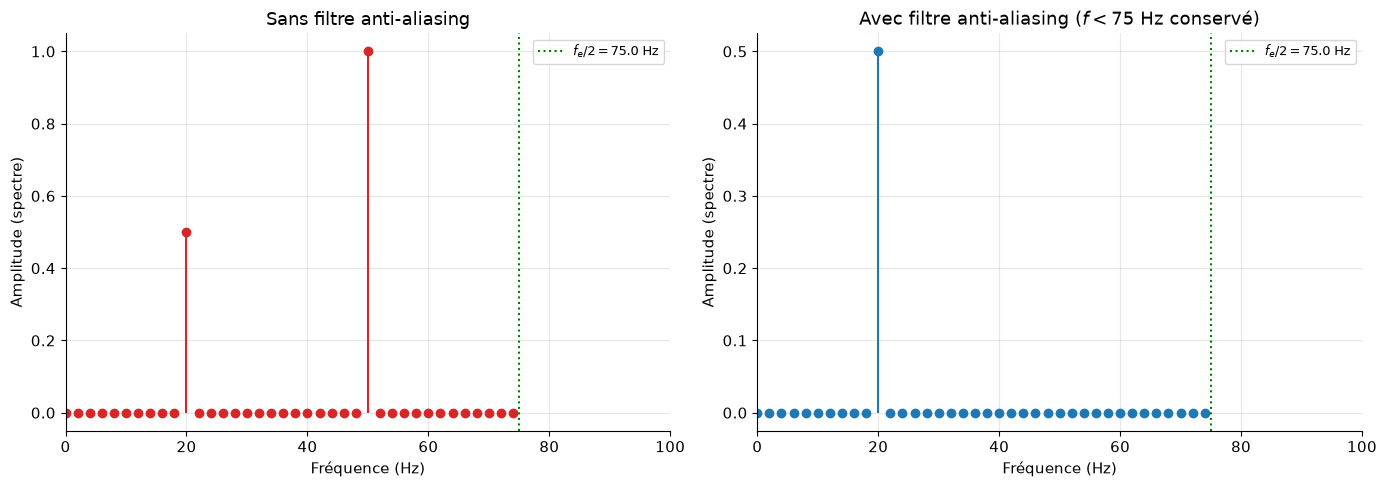

ANALYSE DES FRÉQUENCES APPARENTES
Fréquence d'échantillonnage : fe = 150 Hz (Nyquist fe/2 = 75.0 Hz)
  f (Hz) |   f > fe/2 ? |   f_alias (Hz)
---------------------------------------------
      20 |          non |          20.00
     100 |          oui |          50.00
     200 |          oui |          50.00


In [10]:
# =====================================================
# Exercice 4 — Effet du filtrage anti-aliasing
# =====================================================
fs_sim = 4000                 # fréquence de simulation haute résolution
T = 0.5                       # durée
t_sim = np.linspace(0, T, int(T*fs_sim), endpoint=False)

freqs_signal = [20, 100, 200]
x_sim = np.sum([np.cos(2*np.pi*f*t_sim) for f in freqs_signal], axis=0)

# --- Échantillonnage sans filtre ---
fe = 150
t_ech = np.arange(0, T, 1/fe)
x_ech = np.sum([np.cos(2*np.pi*f*t_ech) for f in freqs_signal], axis=0)

# --- Filtrage anti-aliasing idéal : on ne garde que f < fe/2 ---
f_coupure = fe/2
freqs_filtrees = [f for f in freqs_signal if f < f_coupure]
x_ech_filtre = np.sum([np.cos(2*np.pi*f*t_ech) for f in freqs_filtrees], axis=0)

# --- FFT ---
def spectre(x, fe):
    N = len(x)
    X = np.fft.rfft(x) / N
    freqs = np.fft.rfftfreq(N, 1/fe)
    return freqs, np.abs(X)

freqs_fft, X_sans = spectre(x_ech, fe)
_,          X_avec = spectre(x_ech_filtre, fe)

# Fréquences apparentes théoriques
aliases = [(f, frequence_alias(f, fe)) for f in freqs_signal]

# --- Tracés ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

axes[0].stem(freqs_fft, X_sans, basefmt=' ', linefmt='C3-', markerfmt='C3o')
axes[0].axvline(f_coupure, color='green', ls=':', lw=1.5,
                label=rf'$f_e/2 = {f_coupure}$ Hz')
axes[0].set_title('Sans filtre anti-aliasing')
axes[0].set_xlabel('Fréquence (Hz)')
axes[0].set_ylabel('Amplitude (spectre)')
axes[0].set_xlim(0, 100)
axes[0].legend(fontsize=9)

axes[1].stem(freqs_fft, X_avec, basefmt=' ', linefmt='C0-', markerfmt='C0o')
axes[1].axvline(f_coupure, color='green', ls=':', lw=1.5,
                label=rf'$f_e/2 = {f_coupure}$ Hz')
axes[1].set_title('Avec filtre anti-aliasing ($f < 75$ Hz conservé)')
axes[1].set_xlabel('Fréquence (Hz)')
axes[1].set_ylabel('Amplitude (spectre)')
axes[1].set_xlim(0, 100)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

print("=" * 65)
print("ANALYSE DES FRÉQUENCES APPARENTES")
print("=" * 65)
print(f"Fréquence d'échantillonnage : fe = {fe} Hz (Nyquist fe/2 = {f_coupure} Hz)")
print(f"{'f (Hz)':>8} | {'f > fe/2 ?':>12} | {'f_alias (Hz)':>14}")
print("-" * 45)
for f, fa in aliases:
    flag = "oui" if f > f_coupure else "non"
    print(f"{f:>8} | {flag:>12} | {fa:>14.2f}")

### 📝 Corrigé — Exercice 4

**Sans filtre anti-aliasing** — Les trois composantes (20, 100, 200 Hz) rentrent dans le convertisseur. Après échantillonnage à 150 Hz :

- **20 Hz** : $20 < 75$ → reste à **20 Hz**.
- **100 Hz** : $100 > 75$ → alias = $|100 - 150| = 50$ Hz.
- **200 Hz** : $200 > 75$ → alias = $|200 - 150| = 50$ Hz.

Les deux composantes hautes se replient **sur la même fréquence 50 Hz** : elles s'additionnent (ou s'annulent selon leur phase). On observe donc dans la bande utile **20 Hz + 50 Hz**, alors que le signal original n'a **pas** de composante à 50 Hz. **Résultat faussé.**

**Avec filtre anti-aliasing ($f < 75$ Hz)** — Seule la composante à 20 Hz subsiste. Après échantillonnage, le spectre observé est **fidèle** : une seule raie à 20 Hz. Le signal numérisé est donc un **reflet correct** du signal analogique d'origine (bande limitée).

> 🔑 **Conclusion** — Le filtre anti-aliasing **élimine physiquement** les composantes au-delà de $f_e/2$ *avant* qu'elles ne se replient. C'est la seule manière *propre* de garantir la validité de la numérisation. Un filtre passe-bas **numérique** appliqué après échantillonnage ne peut rien contre l'aliasing : les fréquences repliées sont **déjà** mélangées au signal utile.

> 💡 **En pratique** — Les CAN modernes (audio, instrumentation) intègrent souvent un **filtre anti-aliasing analogique** suivi d'un **sur-échantillonnage** ($f_e$ très supérieure à 2 $f_{max}$) puis d'une **décimation numérique**. Cette astuce relâche énormément les contraintes sur le filtre analogique (qui peut alors avoir une pente douce).

# 5. Synthèse — Les 4 idées-force de la semaine

1. **Le théorème de Nyquist-Shannon fixe la frontière.** Pour reconstruire exactement un signal à bande limitée $f_{max}$, il faut $f_e > 2 f_{max}$. C'est une condition **nécessaire ET suffisante**.

2. **L'aliasing est une conséquence spectrale.** Échantillonner périodise le spectre à $f_e$. Si $f_e < 2 f_{max}$, les répliques se chevauchent et une fréquence $f$ se replie à $|f - k f_e|$.

3. **La quantification introduit un bruit de $\Delta^2/12$.** Pour un sinus pleine échelle, ce bruit donne $\mathrm{SQNR} = 6{,}02 N + 1{,}76$ dB. **1 bit = +6 dB.**

4. **Le filtre anti-aliasing est non négociable.** Une fois l'aliasing produit, aucune opération numérique ne peut le corriger. Il faut **filtrer avant d'échantillonner**.

> 🔑 **En une phrase** — *Un bon convertisseur, c'est un bon filtre anti-aliasing et une bonne résolution : le reste (échantillonnage, blocage, lissage) est de la mécanique bien maîtrisée.*

# 6. Livrable Semaine 3

- **Remplir les cellules de code** avec vos propres solutions (les corrigés fournis peuvent être consultés pour vérification).
- **Répondre aux questions théoriques** dans les cellules markdown.
- **Inclure des commentaires explicatifs** dans le code.
- **Rendre le notebook complet** (toutes les cellules exécutées, sorties visibles).

**Points à vérifier avant rendu** :

- [ ] Toutes les cellules s'exécutent sans erreur (`Kernel → Restart & Run All`).
- [ ] Les figures sont bien visibles et lisibles.
- [ ] Les réponses numériques (Hz, dB, MSE) sont présentes pour chaque exercice.
- [ ] Les conclusions **interprétatives** (pourquoi ? conséquence ?) sont rédigées.

**Date de rendu** : à définir par l'enseignant.